# KHAI PHÁ DỮ LIỆU — LAB 1 · Phần 2 · Bài 5a (Trang 45): Luật kết hợp — Germany, min_sup = 5%, min_conf = 50%

            | | |
            |---|---|
            | **Sinh viên** | Phan Quốc Thắng |
            | **MSSV** | 6451071073 |
            | **Lớp** | CNTT-K64 |
            | **GVHD** | ThS. Nguyễn Thiện Dương |

            Thực hiện lại bài tập lập trình ở phần hướng dẫn chung (Online Retail) với nước **Germany**,
**min_sup = 5%** và **min_conf = 50%**.

## Khai báo thông tin sinh viên & thư viện

In [1]:
HO_TEN = "Phan Quốc Thắng"
MSSV = "6451071073"
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
SEED = int(MSSV[-4:])          # seed lấy từ MSSV để kết quả tái lập được
rng = np.random.default_rng(SEED)
DATA = "../data/"

from scipy.sparse import coo_matrix
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

COUNTRY, MIN_SUP, MIN_CONF = "Germany", 0.05, 0.5

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


## Câu 1: Đọc dữ liệu và làm sạch (Description, InvoiceNo, hoá đơn tín dụng)

In [2]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
df = pd.read_excel(DATA + "Online Retail.xlsx")
print("Kích thước ban đầu:", df.shape)
df["Description"] = df["Description"].str.strip()
df = df.dropna(axis=0, subset=["InvoiceNo"])
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df = df[~df["InvoiceNo"].str.contains("C")]
print("Kích thước sau làm sạch:", df.shape)
print(f"Số dòng của {COUNTRY}:", (df["Country"] == COUNTRY).sum())
display(df[df["Country"] == COUNTRY].head())

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


Kích thước ban đầu: (541909, 8)


Kích thước sau làm sạch: (532621, 8)
Số dòng của Germany: 9042


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
1109,536527,22809,SET OF 6 T-LIGHTS SANTA,6,2010-12-01 13:04:00,2.95,12662.0,Germany
1110,536527,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,6,2010-12-01 13:04:00,2.55,12662.0,Germany
1111,536527,84945,MULTI COLOUR SILVER T-LIGHT HOLDER,12,2010-12-01 13:04:00,0.85,12662.0,Germany
1112,536527,22242,5 HOOK HANGER MAGIC TOADSTOOL,12,2010-12-01 13:04:00,1.65,12662.0,Germany
1113,536527,22244,3 HOOK HANGER MAGIC GARDEN,12,2010-12-01 13:04:00,1.95,12662.0,Germany


**Nhận xét:**

- Sau làm sạch còn 532 621 dòng, trong đó **Germany có 9 042 dòng**. Đây là nước có nhiều dữ liệu thứ hai sau Anh.

## Câu 2: Lọc hoá đơn theo quốc gia, gom nhóm và chuyển về one-hot encoding, xoá POSTAGE

In [3]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
basket = (df[df["Country"] == COUNTRY]
          .groupby(["InvoiceNo", "Description"])["Quantity"].sum()
          .unstack().reset_index().fillna(0).set_index("InvoiceNo"))
print("Hot encoding (số lượng) — kích thước:", basket.shape)
display(basket.iloc[:5, :8])

def encode_units(x):
    return 1 if x > 0 else 0
basket_sets = basket.map(encode_units).astype(bool)
basket_sets = basket_sets.drop(columns=["POSTAGE"], errors="ignore")
print("One-hot sau khi xoá POSTAGE — kích thước:", basket_sets.shape)
display(basket_sets.iloc[:5, :8].astype(int))

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
Hot encoding (số lượng) — kích thước: (457, 1695)


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY
InvoiceNo,,,,,,,,
536527,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536840,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536861,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536967,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536983,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


One-hot sau khi xoá POSTAGE — kích thước: (457, 1694)


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY
InvoiceNo,,,,,,,,
536527,0,0,0,0,0,0,0,0
536840,0,0,0,0,0,0,0,0
536861,0,0,0,0,0,0,0,0
536967,0,0,0,0,0,0,0,0
536983,0,0,0,0,0,0,0,0


**Nhận xét:**

- Dữ liệu Đức gồm **457 hoá đơn × 1 695 mặt hàng**, sau khi xoá POSTAGE còn 1 694 mặt hàng. Kích thước nhỏ nên có thể dùng `unstack()` dạng dense như hướng dẫn.
- POSTAGE ở Đức xuất hiện trong hầu hết hoá đơn (phí ship quốc tế). Nếu không xoá thì gần như luật nào cũng có POSTAGE ở vế phải.

## Câu 3: Tìm tập phổ biến bằng Apriori

In [4]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
t0 = time.perf_counter()
frequent_ap = apriori(basket_sets, min_support=MIN_SUP, use_colnames=True)
t_ap = time.perf_counter() - t0
frequent_ap["length"] = frequent_ap["itemsets"].apply(len)
print(f"min_sup = {MIN_SUP:.0%} | Số tập phổ biến: {len(frequent_ap)} | thời gian: {t_ap:.3f} s")
print("Số tập theo độ dài:", frequent_ap["length"].value_counts().sort_index().to_dict())
display(frequent_ap.sort_values("support", ascending=False).head(10))

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
min_sup = 5% | Số tập phổ biến: 59 | thời gian: 0.006 s
Số tập theo độ dài: {1: 50, 2: 9}


,support,itemsets,length
35,0.245077,frozenset({ROUND SNACK BOXES SET OF4 WOODLAND}),1
34,0.157549,frozenset({ROUND SNACK BOXES SET OF 4 FRUITS}),1
24,0.137856,frozenset({PLASTERS IN TIN WOODLAND ANIMALS}),1
31,0.137856,frozenset({REGENCY CAKESTAND 3 TIER}),1
56,0.131291,"frozenset({ROUND SNACK BOXES SET OF4 WOODLAND,...",2
48,0.126915,frozenset({WOODLAND CHARLOTTE BAG}),1
21,0.115974,frozenset({PLASTERS IN TIN CIRCUS PARADE}),1
22,0.107221,frozenset({PLASTERS IN TIN SPACEBOY}),1
0,0.102845,frozenset({6 RIBBONS RUSTIC CHARM}),1
44,0.102845,frozenset({SPACEBOY LUNCH BOX}),1


**Nhận xét:**

- Với min_sup = 5% (≥ 23 hoá đơn) có **59 tập phổ biến**, gồm 50 tập 1 phần tử và 9 tập 2 phần tử.
- Mặt hàng phổ biến nhất là ROUND SNACK BOXES SET OF4 WOODLAND (24.5% hoá đơn). Cặp {ROUND SNACK BOXES SET OF 4 FRUITS, … WOODLAND} xuất hiện trong 13.1% hoá đơn, cao hơn hầu hết các mặt hàng đơn lẻ.

## Câu 4: Tạo luật kết hợp và in ra các luật

In [5]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
rules_ap = association_rules(frequent_ap, metric="confidence", min_threshold=MIN_CONF)
rules_ap["antecedents"] = rules_ap["antecedents"].apply(lambda x: ", ".join(sorted(x)))
rules_ap["consequents"] = rules_ap["consequents"].apply(lambda x: ", ".join(sorted(x)))
rules_ap = rules_ap.sort_values(["confidence", "lift"], ascending=False).reset_index(drop=True)
print(f"min_conf = {MIN_CONF:.0%} | Số luật tìm được: {len(rules_ap)}")
display(rules_ap[["antecedents", "consequents", "support", "confidence", "lift"]].round(4))
for _, r in rules_ap.iterrows():
    print(f"{{{r['antecedents']}}} => {{{r['consequents']}}}  (sup = {r['support']:.4f}, conf = {r['confidence']:.4f}, lift = {r['lift']:.2f})")

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
min_conf = 50% | Số luật tìm được: 8


,antecedents,consequents,support,confidence,lift
0,RED RETROSPOT CHARLOTTE BAG,WOODLAND CHARLOTTE BAG,0.0591,0.8438,6.6482
1,ROUND SNACK BOXES SET OF 4 FRUITS,ROUND SNACK BOXES SET OF4 WOODLAND,0.1313,0.8333,3.4003
2,SPACEBOY LUNCH BOX,ROUND SNACK BOXES SET OF4 WOODLAND,0.0700,0.6809,2.7781
3,PLASTERS IN TIN CIRCUS PARADE,PLASTERS IN TIN WOODLAND ANIMALS,0.0678,0.5849,4.2429
4,PLASTERS IN TIN SPACEBOY,PLASTERS IN TIN WOODLAND ANIMALS,0.0613,0.5714,4.1451
5,PLASTERS IN TIN WOODLAND ANIMALS,ROUND SNACK BOXES SET OF4 WOODLAND,0.0744,0.5397,2.2021
6,ROUND SNACK BOXES SET OF4 WOODLAND,ROUND SNACK BOXES SET OF 4 FRUITS,0.1313,0.5357,3.4003
7,WOODLAND CHARLOTTE BAG,ROUND SNACK BOXES SET OF4 WOODLAND,0.0635,0.5000,2.0402


{RED RETROSPOT CHARLOTTE BAG} => {WOODLAND CHARLOTTE BAG}  (sup = 0.0591, conf = 0.8438, lift = 6.65)
{ROUND SNACK BOXES SET OF 4 FRUITS} => {ROUND SNACK BOXES SET OF4 WOODLAND}  (sup = 0.1313, conf = 0.8333, lift = 3.40)
{SPACEBOY LUNCH BOX} => {ROUND SNACK BOXES SET OF4 WOODLAND}  (sup = 0.0700, conf = 0.6809, lift = 2.78)
{PLASTERS IN TIN CIRCUS PARADE} => {PLASTERS IN TIN WOODLAND ANIMALS}  (sup = 0.0678, conf = 0.5849, lift = 4.24)
{PLASTERS IN TIN SPACEBOY} => {PLASTERS IN TIN WOODLAND ANIMALS}  (sup = 0.0613, conf = 0.5714, lift = 4.15)
{PLASTERS IN TIN WOODLAND ANIMALS} => {ROUND SNACK BOXES SET OF4 WOODLAND}  (sup = 0.0744, conf = 0.5397, lift = 2.20)
{ROUND SNACK BOXES SET OF4 WOODLAND} => {ROUND SNACK BOXES SET OF 4 FRUITS}  (sup = 0.1313, conf = 0.5357, lift = 3.40)
{WOODLAND CHARLOTTE BAG} => {ROUND SNACK BOXES SET OF4 WOODLAND}  (sup = 0.0635, conf = 0.5000, lift = 2.04)


**Nhận xét:**

- Có **8 luật** thoả min_conf = 50%. Luật tin cậy nhất là {RED RETROSPOT CHARLOTTE BAG} ⇒ {WOODLAND CHARLOTTE BAG} (conf 84.4%, lift 6.65). Tiếp theo là {ROUND SNACK BOXES SET OF 4 FRUITS} ⇒ {… WOODLAND} (conf 83.3%, support 13.1%, là luật có support cao nhất).
- Khác với Anh, các luật ở Đức xoay quanh **đồ dùng cho trẻ em/đi học**: hộp đựng đồ ăn, băng dán cá nhân PLASTERS IN TIN, hộp cơm SPACEBOY. ROUND SNACK BOXES WOODLAND là mặt hàng "trung tâm", xuất hiện ở vế phải của 4/8 luật.

## Câu 5: Biểu diễn độ tin cậy, độ hỗ trợ của tập luật lên đồ thị phân tán

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


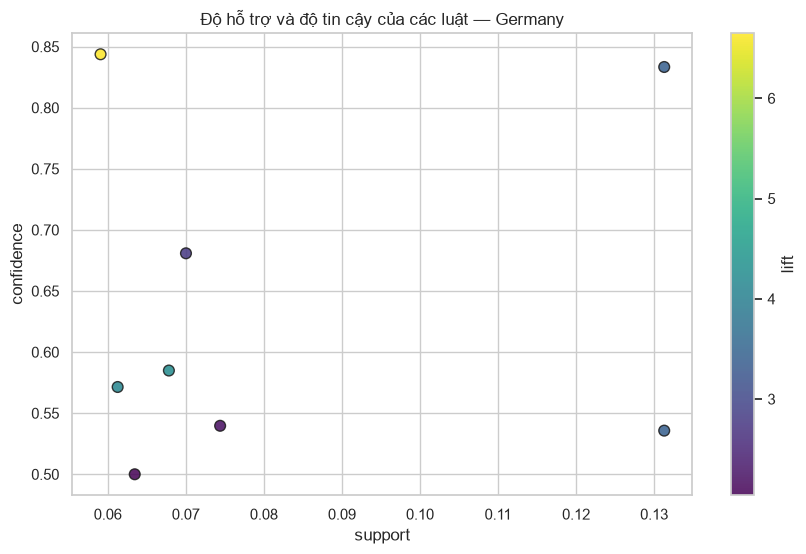

In [6]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(rules_ap["support"], rules_ap["confidence"], c=rules_ap["lift"], cmap="viridis",
                s=60, alpha=0.85, edgecolors="k")
plt.colorbar(sc, label="lift")
ax.set_title(f"Độ hỗ trợ và độ tin cậy của các luật — {COUNTRY}"); ax.set_xlabel("support"); ax.set_ylabel("confidence")
plt.show()

**Nhận xét:**

- 8 luật có support 0.059 – 0.131 và confidence 0.50 – 0.84, đều cao hơn so với UK vì số hoá đơn ít và hành vi mua tập trung hơn.
- Luật về hộp snack có support cao nhất (0.131) nhưng lift vừa phải (khoảng 3.4). Luật túi Charlotte có support thấp (0.059) nhưng lift cao nhất (6.65), cho thấy hai mẫu túi này gần như luôn được mua cùng nhau.

## Câu 6: Tìm tập phổ biến và luật kết hợp bằng FP-Growth và so sánh với Apriori

In [7]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
t0 = time.perf_counter()
frequent_fp = fpgrowth(basket_sets, min_support=MIN_SUP, use_colnames=True)
t_fp = time.perf_counter() - t0
rules_fp = association_rules(frequent_fp, metric="confidence", min_threshold=MIN_CONF)
rules_fp["antecedents"] = rules_fp["antecedents"].apply(lambda x: ", ".join(sorted(x)))
rules_fp["consequents"] = rules_fp["consequents"].apply(lambda x: ", ".join(sorted(x)))
display(rules_fp.sort_values(["confidence", "lift"], ascending=False)[["antecedents", "consequents", "support", "confidence", "lift"]].round(4).head(10).reset_index(drop=True))
same_items = set(frequent_ap["itemsets"]) == set(frequent_fp["itemsets"])
same_rules = set(zip(rules_ap.antecedents, rules_ap.consequents)) == set(zip(rules_fp.antecedents, rules_fp.consequents))
display(pd.DataFrame({"Apriori": [len(frequent_ap), len(rules_ap), round(t_ap, 3)],
                      "FP-Growth": [len(frequent_fp), len(rules_fp), round(t_fp, 3)]},
                     index=["Số tập phổ biến", "Số luật", "Thời gian tìm tập phổ biến (s)"]))
print("Tập phổ biến giống nhau:", same_items, "| Tập luật giống nhau:", same_rules)

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


,antecedents,consequents,support,confidence,lift
0,RED RETROSPOT CHARLOTTE BAG,WOODLAND CHARLOTTE BAG,0.0591,0.8438,6.6482
1,ROUND SNACK BOXES SET OF 4 FRUITS,ROUND SNACK BOXES SET OF4 WOODLAND,0.1313,0.8333,3.4003
2,SPACEBOY LUNCH BOX,ROUND SNACK BOXES SET OF4 WOODLAND,0.0700,0.6809,2.7781
3,PLASTERS IN TIN CIRCUS PARADE,PLASTERS IN TIN WOODLAND ANIMALS,0.0678,0.5849,4.2429
4,PLASTERS IN TIN SPACEBOY,PLASTERS IN TIN WOODLAND ANIMALS,0.0613,0.5714,4.1451
5,PLASTERS IN TIN WOODLAND ANIMALS,ROUND SNACK BOXES SET OF4 WOODLAND,0.0744,0.5397,2.2021
6,ROUND SNACK BOXES SET OF4 WOODLAND,ROUND SNACK BOXES SET OF 4 FRUITS,0.1313,0.5357,3.4003
7,WOODLAND CHARLOTTE BAG,ROUND SNACK BOXES SET OF4 WOODLAND,0.0635,0.5000,2.0402


,Apriori,FP-Growth
Số tập phổ biến,59.000,59.000
Số luật,8.000,8.000
Thời gian tìm tập phổ biến (s),0.006,0.012


Tập phổ biến giống nhau: True | Tập luật giống nhau: True


**Nhận xét:**

- FP-Growth cho **cùng 59 tập phổ biến và 8 luật** như Apriori.
- Thời gian của cả hai thuật toán đều chỉ vài mili-giây (Apriori khoảng 0.006 s, FP-Growth khoảng 0.012 s) vì dữ liệu Đức chỉ có 457 hoá đơn. Ở quy mô này, chênh lệch không có ý nghĩa thực tế.